Convert nielson_conversion.json to nielson_data.csv

In [7]:
# Make the Nielson JSON easy to read as a spreadsheet
from nielson_data import NielsonDataCSVConverter

# Define file paths
json_file = "nielson_ome.json"
csv_file = "nielson_data.csv"

# Create an instance of the converter
converter = NielsonDataCSVConverter(json_file, csv_file)

# Convert the JSON to CSV
converter.convert_to_csv()

JSON data has been successfully converted to nielson_data.csv


Add priority assignments to each opioid in nielson_conversions.json

In [6]:
# Import the class
from nielson_data import NielsonDataPriorityUpdater

# Define the JSON file path
json_file = "nielson_ome.json"

# Create an instance of the updater
updater = NielsonDataPriorityUpdater(json_file)

# Define the priority dictionary
priority_dict = {
    1: ['oral_hydromorphone', 'oral_morphine', 'oral_oxycodone','iv_hydromorphone','iv_morphine'],
    2: ['oral_codeine', 'oral_hydrocodone', 'oral_methadone', 'oral_oxymorphone',
        'oral_tapentadol','oral_tramadol','sublingual_buprenorphine','transdermal_fentanyl',
        'iv_fentanyl','sc_fentanyl']
}

# Update the priorities in the JSON file
updater.update_priorities(priority_dict)

Updated JSON data has been saved to nielson_ome.json


Calculate the equivalent opioids from nielson_ome.json

In [2]:
# Conversion Service
from opioid import Opioid
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS

conversion_service = ConversionService(NIELSON_CONVERSIONS)

iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone")
oral_morphine = Opioid(administration_method="oral", substance="morphine")

random_dose = conversion_service.generate_random_dose(iv_fentanyl)
print(f"Random dose for {iv_fentanyl.administration_method}_{iv_fentanyl.substance}: {random_dose:.2f} {iv_fentanyl.unit}")

equivalent_dose_oral_morphine = conversion_service.calculate_expected_dose(random_dose, iv_fentanyl, oral_morphine)
print(f"Equivalent dose for {oral_morphine.administration_method}_{oral_morphine.substance}: {equivalent_dose_oral_morphine:.2f} {oral_morphine.unit}")

Random dose for iv_fentanyl: 56.23 mcg/day
Equivalent dose for oral_morphine: 11.25 mg/day


Construct a prompt

In [3]:
# Prompt Service
from prompt_service import PromptService, PromptedOpioidConversion
from conversion_service import ConversionService
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the PromptService
prompt_service = PromptService(ConversionService(NIELSON_CONVERSIONS))

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object without specifying `from_dose` or `conversion_service`
prompted_conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    model="gpt-4.1-mini",)

# Generate the prompt using the PromptService instance
generated_prompt = prompted_conversion.generate_prompt(prompt_service)

# Print the generated prompt
print("Generated Prompt:")
print(generated_prompt)

# Print the randomly generated `from_dose` and calculated `expected_to_dose`
print(f"\nRandomly Generated Dose: {prompted_conversion.from_dose:.2f} {iv_fentanyl.unit}")
print(f"Expected Dose: {prompted_conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")

Generated Prompt:
Convert 122.32 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 122.32 mcg/day of fentanyl (iv)?

Use the following conversion factor(s):
0.2 OME: 1 mcg/day of fentanyl (iv) is equivalent to 0.2 mg/day morphine (oral).
0.2 OME for fentanyl (iv) means 10 mg/day of morphine (oral) is equivalent to 50.00 mcg/day of fentanyl (iv).
And 120 mg/day of morphine (oral) is equivalent to 600.00 mcg/day of fentanyl (iv).

Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.

Randomly Generated Dose: 122.32 mcg/day
Expected Dose: 24.46 mg/day


Ask the model for the equivalent opioid dose

In [6]:
# Run a single conversion with an instance of PromptedOpioidConversion
from conversion_service import ConversionService
from prompt_service import PromptService, PromptedOpioidConversion
from nielson_data import NIELSON_CONVERSIONS
from opioid import Opioid

# Initialize the OpenAI client once
PromptedOpioidConversion.initialize_client()

# Define opioids
iv_fentanyl = Opioid(administration_method="iv", substance="fentanyl", unit="mcg/hour")
oral_hydromorphone = Opioid(administration_method="oral", substance="hydromorphone", unit="mg/day")

# Create a PromptedOpioidConversion object
conversion = PromptedOpioidConversion(
    from_opioid=iv_fentanyl,
    include_nielson=True,
    include_examples=True
)

# Generate the prompt
conversion.generate_prompt(prompt_service=PromptService(ConversionService(NIELSON_CONVERSIONS)))

# Query the model
observed_dose = conversion.ask_model()

# Print the results
print("Generated Prompt:")
print(conversion.prompt)
print(f"Observed Dose: {observed_dose:.2f} {oral_hydromorphone.unit}")
print(f"Expected Dose: {conversion.expected_to_dose:.2f} {oral_hydromorphone.unit}")
print(f"Ratio Observed/Expected: {conversion.ratio_observed_expected:.2f}")

Generated Prompt:
Convert 148.47 mcg/day of fentanyl (iv) to mg/day of morphine (oral).
How many mg/day of morphine (oral) is equivalent to 148.47 mcg/day of fentanyl (iv)?

Use the following conversion factor(s):
0.2 OME: 1 mcg/day of fentanyl (iv) is equivalent to 0.2 mg/day morphine (oral).
0.2 OME for fentanyl (iv) means 10 mg/day of morphine (oral) is equivalent to 50.00 mcg/day of fentanyl (iv).
And 120 mg/day of morphine (oral) is equivalent to 600.00 mcg/day of fentanyl (iv).

Express the response in the format {'calculated dose': value}.  Do not include any additional text in your response, only the dictionary.
Observed Dose: 29.69 mg/day
Expected Dose: 29.69 mg/day
Ratio Observed/Expected: 1.00


Run an experiment converting all opioids to oral morphine across prompting conditions and models

In [2]:
# Run an experiment
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize the OpenAI client once
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list = OpioidPairGenerator(lambda priority: priority <= 2 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=False)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False},
    {"include_nielson": True, "include_examples": True}
]

models = ["gpt-4.1-mini", "gpt-3.5-turbo"]

# Run an experiment
experiment = Experiment(opioid_list, prompt_conditions, models, repetitions=25)
experiment.run()
experiment.save_to_csv("experiment_results.csv")

# Print the experiment ID
print(f"Experiment ID: {experiment.experiment_id}")

Error during conversion: Error parsing the model response. Response: {"calculated dose": 102.285}
Error during conversion: Error parsing the model response. Response: {"calculated dose": 39.69}
Results appended to experiment_results.csv
Experiment ID: 4


Run an experiment converting opioids to other opioids, across prompting conditions and models

In [3]:
# Run an experiment
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize the OpenAI client once
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list = OpioidPairGenerator(lambda priority: priority == 1 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=True, use_permutations=True)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False},
    {"include_nielson": True, "include_examples": True}
]

models = ["gpt-4.1-mini", "gpt-3.5-turbo"]

# Run an experiment
experiment = Experiment(opioid_list, prompt_conditions, models, repetitions=25)
experiment.run()
experiment.save_to_csv("experiment_results.csv")

# Print the experiment ID
print(f"Experiment ID: {experiment.experiment_id}")

Error during conversion: Error parsing the model response. Response: {"calculated dose": 87.0}
Results appended to experiment_results.csv
Experiment ID: 5


Visualize the results of an experiment

UnboundLocalError: cannot access local variable 'np' where it is not associated with a value

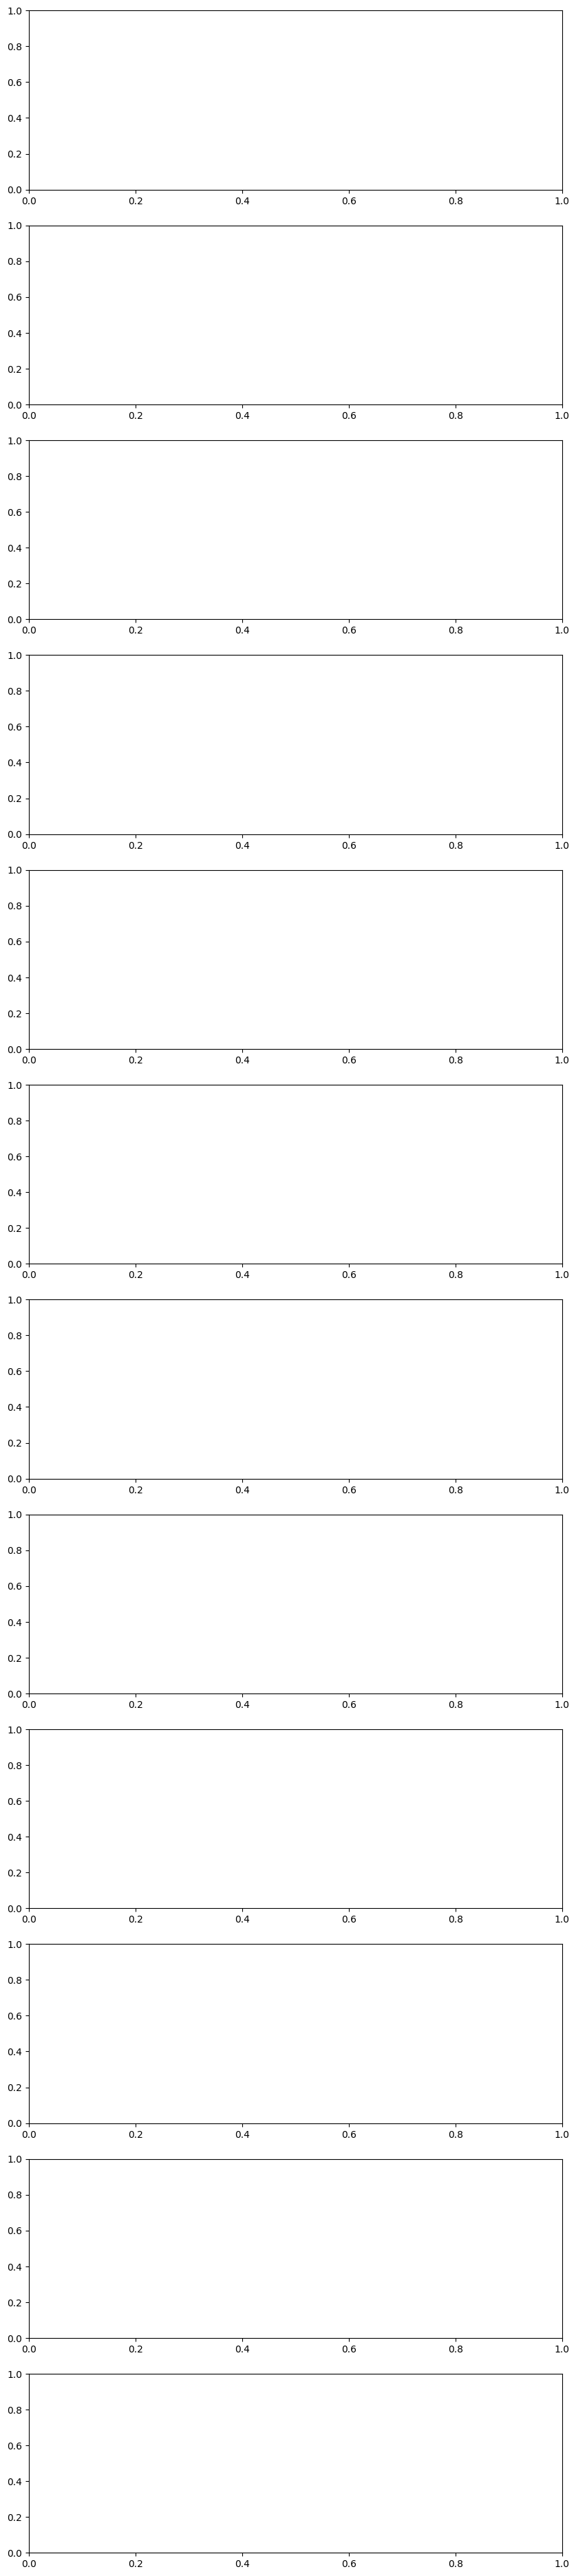

In [2]:
from experiment_batch import ExperimentBatch
import matplotlib.pyplot as plt

batch = ExperimentBatch(
    csv_file="experiment_results.csv",
    models=["gpt-4.1-mini", "gpt-3.5-turbo"],
    prompt_conditions_list=[
        {"include_nielson": False, "include_examples": False},
        {"include_nielson": True, "include_examples": False},
        {"include_nielson": True, "include_examples": True}
    ],
    experiment_ids=[4, 5],
    experiment_names={
        4: "to oral morphine",
        5: "non-OME pairs"
    }
)

# Define metadata
metadata = {
    'title': 'Opioid Conversion Experiment Comparison',
    'author': 'Tanya Marton',
    'subject': 'LLM model comparison across prompting conditions',
    'keywords': 'opioid conversion, GPT models, prompt engineering'
}

# Generate the PDF
batch.generate_pdf(
    output_pdf="experiment_comparison.pdf",
    plot_types=["scatter", "ratio_regression", "cdf", "histogram"],
    figsize=(10, 48),
    metadata=metadata,
    include_summary_plots=True,
    colormap='parula'
)

print("PDF generated: experiment_comparison.pdf")

Run with more models

In [1]:
# Run an experiment converting all opioids to oral morphine across prompting conditions and models
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize all clients
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list = OpioidPairGenerator(lambda priority: priority <= 2 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=False)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": False, "include_examples": False},
    {"include_nielson": True, "include_examples": False}
]

models = [
    "claude-3-5-haiku-20241022",
    "llama-3.3-70b-versatile",
    "models/gemini-2.5-flash"
]

# Run experiment
experiment = Experiment(opioid_list, prompt_conditions, models, repetitions=25)
experiment.run()
experiment.save_to_csv("experiment_results.csv")

# Print the experiment ID
print(f"Experiment ID: {experiment.experiment_id}")

Error during conversion: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/usage?tab=rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 10
Please retry in 35.999160507s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerMinutePerProjectPerModel-FreeTier"
  quota_dimensions {
    key: "model"
    value: "gemini-2.5-flash"
  }
  quota_dimensions {
    key: "location"
    value: "global"
  }
  quota_value: 10
}
, retry_delay {
  seconds: 35
}
]
Error during conversion: 429 You exceeded your current quota, please check your plan and billing

In [ ]:
# Run an experiment converting opioids across prompting conditions and models
from prompt_service import PromptedOpioidConversion
from opioid import OpioidPairGenerator
from experiment import Experiment

# Initialize all clients
PromptedOpioidConversion.initialize_client()

# Generate opioid pairs
opioid_list = OpioidPairGenerator(lambda priority: priority == 1 if priority else False)\
    .generate_opioid_list_or_pairs(pairs=True, use_permutations=True)

# Define prompt conditions
prompt_conditions = [
    {"include_nielson": True, "include_examples": False}
]

models = [
    "claude-3-5-haiku-20241022",
    "llama-3.3-70b-versatile",
    "models/gemini-2.5-flash"
]

# Run experiment
experiment = Experiment(opioid_list, prompt_conditions, models, repetitions=25)
experiment.run()
experiment.save_to_csv("experiment_results.csv")

# Print the experiment ID
print(f"Experiment ID: {experiment.experiment_id}")

Error during conversion: Gemini failed to generate response:
Finish Reason: MAX_TOKENS (ran out of tokens)
Safety Ratings:
  (none)
Prompt Feedback: 
Prompt (first 200 chars): Convert 5.74 mg/day of hydromorphone (oral) to mg/day of oxycodone (oral).
How many mg/day of oxycodone (oral) is equivalent to 5.74 mg/day of hydromorphone (oral)?


Express the response in the forma...
Error during conversion: Gemini failed to generate response:
Finish Reason: MAX_TOKENS (ran out of tokens)
Safety Ratings:
  (none)
Prompt Feedback: 
Prompt (first 200 chars): Convert 7.77 mg/day of hydromorphone (oral) to mg/day of oxycodone (oral).
How many mg/day of oxycodone (oral) is equivalent to 7.77 mg/day of hydromorphone (oral)?


Express the response in the forma...
Error during conversion: Gemini failed to generate response:
Finish Reason: MAX_TOKENS (ran out of tokens)
Safety Ratings:
  (none)
Prompt Feedback: 
Prompt (first 200 chars): Convert 7.77 mg/day of hydromorphone (oral) to mg/day of oxycodo

In [1]:
# Summarize all experiments in the CSV
from experiment_batch import ExperimentBatch

ExperimentBatch.summarize_csv("experiment_results.csv")

FULL CSV SUMMARY: experiment_results.csv

Total entries: 7531
Unique experiments: 13
Unique models: 5
Experiment IDs: [np.int64(4), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(63), np.int64(160), np.int64(941)]
Models: ['claude-3-5-haiku-20241022', 'gpt-3.5-turbo', 'gpt-4.1-mini', 'llama-3.3-70b-versatile', 'models/gemini-2.5-flash']

COMPREHENSIVE SUMMARY TABLE
 experiment_id                     model  count       priority  pairs use_permutations include_nielson include_examples  from_opioids_count  to_opioids_count
             4             gpt-3.5-turbo   1125 Priority 1 & 2  False             None     False, True      False, True                  15                 1
             4              gpt-4.1-mini   1123 Priority 1 & 2  False             None     False, True      False, True                  15                 1
             5             gpt-3.5-turbo    900     Priority 1   True     

,experiment_id,model,count,priority,pairs,use_permutations,include_nielson,include_examples,from_opioids_count,to_opioids_count
0,4,gpt-3.5-turbo,1125,Priority 1 & 2,False,None,"False, True","False, True",15,1
1,4,gpt-4.1-mini,1123,Priority 1 & 2,False,None,"False, True","False, True",15,1
2,5,gpt-3.5-turbo,900,Priority 1,True,True,"False, True","False, True",4,4
3,5,gpt-4.1-mini,899,Priority 1,True,True,"False, True","False, True",4,4
4,6,claude-3-5-haiku-20241022,4,Priority 1,False,None,True,False,4,1
5,6,llama-3.3-70b-versatile,4,Priority 1,False,None,True,False,4,1
6,8,claude-3-5-haiku-20241022,4,Priority 1,False,None,True,False,4,1
7,8,llama-3.3-70b-versatile,4,Priority 1,False,None,True,False,4,1
8,8,models/gemini-2.5-flash,2,Priority 1,False,None,True,False,4,1
9,9,claude-3-5-haiku-20241022,4,Priority 1,False,None,True,False,4,1


In [ ]:
from experiment_batch import ExperimentBatch
import matplotlib.pyplot as plt

batch = ExperimentBatch(
    csv_file="experiment_results.csv",
    models=["gpt-4.1-mini", "claude-3-5-haiku-20241022", "llama-3.3-70b-versatile", "models/gemini-2.5-flash"],
    prompt_conditions_list=[
        {"include_nielson": False, "include_examples": False},
        {"include_nielson": True, "include_examples": False}
    ],
    experiment_ids=[63, 160],  # Your new experiment ID
    experiment_names={
        63: "non-OME pairs",
        160: "to oral morphine"
    }
)

# Define metadata
metadata = {
    'title': 'Multi-Model Opioid Conversion Experiment',
    'author': 'Tanya Marton',
    'subject': 'LLM comparison: GPT-4, Claude, Llama, Gemini',
    'keywords': 'opioid conversion, multi-model comparison, prompt engineering'
}

# Generate the PDF
batch.generate_pdf(
    output_pdf="four_model_comparison.pdf",
    plot_types=["scatter", "ratio_regression", "cdf", "histogram"],
    figsize=(10, 72),
    metadata=metadata,
    include_summary_plots=True,
    colormap='viridis'
)

print("PDF generated: four_model_comparison.pdf")

PDF generated: four_model_comparison.pdf
